---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 03

- Kevin Wirya Valerian        (13524019)
- Vincent Rionarlie           (13524031)
- Emilio Justin               (13524043)
- Arina Azka                  (13524049)
- Muhammad Aufar Rizqi Kusuma (13524061)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Baseline Model Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

## Overview

Pembatalan pemesanan dapat menyebabkan kamar yang sudah dialokasikan tidak terjual kembali. Prediksi yang baik dapat membantu pengelola akomodasi merencanakan kapasitas, mengirimkan pengingat, dan menyusun kebijakan pembatalan. Tugas ini membangun *classification model* untuk memprediksi apakah suatu pemesanan akan dibatalkan.

## Aim

Notebook ini bertujuan membangun dan mengevaluasi *classification model* dari nol (*from scratch*) untuk memprediksi status pembatalan pemesanan. Prosesnya mencakup pemahaman data, pemisahan *training set* dan *validation set*, *feature preparation*, pemodelan, analisis kesalahan, serta prediksi pada *test set*. Model buatan sendiri dibandingkan dengan implementasi `scikit-learn` sebagai acuan.

## Metric

Penilaian menggunakan *Macro F1*, yaitu rata-rata F1 untuk kelas pemesanan tidak dibatalkan (0) dan dibatalkan (1). Kedua kelas memiliki bobot yang sama sehingga performa pada kelas yang lebih sedikit tetap diperhitungkan.

$$\mathrm{MacroF1}=\frac{1}{2}\sum_{c\in\{0,1\}}\mathrm{F1}_c,\qquad \mathrm{F1}_c=\frac{2\,\mathrm{Precision}_c\,\mathrm{Recall}_c}{\mathrm{Precision}_c+\mathrm{Recall}_c}$$

Metrik dihitung pada *validation set* yang dipisahkan dari *training set*. *Test set* hanya digunakan untuk menghasilkan berkas *submission* dan tidak digunakan untuk memilih model atau mengatur *hyperparameter*.

## Dataset

Dataset kompetisi Tugas Besar 2 IF3170 berisi catatan pemesanan dari suatu properti akomodasi. *Training set* berisi 27.373 pemesanan dengan label `is_canceled`, sedangkan *test set* berisi 6.844 pemesanan tanpa label. Target bernilai 1 jika pemesanan dibatalkan dan 0 jika tidak.

Informasi yang tersedia mencakup jumlah dan riwayat tamu, lama menginap, paket makanan, kategori kamar, kanal pemesanan, harga per malam, waktu kedatangan, serta jumlah permintaan khusus. Dataset memuat *numerical* dan *categorical features*, dengan sejumlah nilai yang kosong. Kolom `id` adalah pengenal pemesanan dan tidak digunakan sebagai *feature* prediksi.

## Approach

Eksperimen dimulai dengan eksplorasi data dan pemeriksaan kualitas. Data dipisahkan menjadi *training set* dan *validation set* sebelum *preprocessing* untuk mencegah kebocoran informasi. Nilai kosong, *categorical features*, dan kebutuhan transformasi numerik ditangani melalui *preprocessing pipeline* yang hanya dipelajari dari *training set*.

Notebook membandingkan implementasi *K-Nearest Neighbors*, *decision tree*, *logistic regression*, *Support Vector Machine*, dan *Naive Bayes* yang dibuat dari nol. Kinerja diukur dengan *Macro F1* dan dibandingkan dengan implementasi `scikit-learn`. Model terpilih kemudian menghasilkan prediksi untuk *test set* dalam format *submission*.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas scikit-learn matplotlib

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    ROOT_DIR   = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'data' / 'train.csv').is_file()), Path.cwd())
    DATA_DIR   = ROOT_DIR / 'data'
    TRAIN_PATH = DATA_DIR / 'train.csv'
    TEST_PATH  = DATA_DIR / 'test.csv'
    OUTPUT_DIR = ROOT_DIR / 'output'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.TRAIN_PATH, dtype={'id': str})
test_df = pd.read_csv(CFG.TEST_PATH, dtype={'id': str})

# Establish the holdout before any target-aware data exploration.
y = train_df['is_canceled'].to_numpy()
if not np.isin(y, (0, 1)).all():
    raise ValueError('Target is expected to contain only labels 0 and 1.')
rng = np.random.default_rng(CFG.SEED)
valid_idx = np.sort(np.concatenate([
    rng.permutation(np.flatnonzero(y == label))[:int(np.ceil(0.2 * np.sum(y == label)))]
    for label in (0, 1)
]))
train_idx = np.setdiff1d(np.arange(len(train_df)), valid_idx)
train_set = train_df.iloc[train_idx].copy()
val_set = train_df.iloc[valid_idx].copy()

print(f'Train: {train_df.shape}  Test: {test_df.shape}')
print(f'Train split: {len(train_set)}  Validation split: {len(val_set)}')

Train: (27373, 19)  Test: (6844, 18)
Train split: 21898  Validation split: 5475


---

# Data Understanding <a name="3"></a>

---

Chart berikut merangkum keseimbangan target, missingness, pola numerik, variasi kategori, dan perubahan distribusi train-test. Analisis berlabel dibatasi ke `train_set`.

## Describe Data

Mulai dengan ukuran dataset, schema, tipe fitur, dan statistik deskriptif sebelum pemodelan.

In [6]:
feature_columns = [column for column in train_df.columns if column not in {'id', 'is_canceled'}]
feature_profile = train_df.drop(columns='is_canceled')
column_profile = pd.DataFrame({
    'dtype': feature_profile.dtypes.astype(str),
    'non_missing': feature_profile.notna().sum(),
    'missing': feature_profile.isna().sum(),
    'missing_pct': feature_profile.isna().mean().mul(100).round(2),
    'unique': feature_profile.nunique(dropna=True),
    'examples': feature_profile.apply(lambda column: ', '.join(column.dropna().astype(str).unique()[:3])),
})
display(column_profile)

dataset_overview = pd.DataFrame({
    'train': [len(train_df), train_df.shape[1], len(feature_columns), train_df.memory_usage(deep=True).sum() / 1024**2],
    'test': [len(test_df), test_df.shape[1], len(feature_columns), test_df.memory_usage(deep=True).sum() / 1024**2],
}, index=['rows', 'columns', 'features', 'memory_mb']).round(2)
display(dataset_overview)

schema_comparison = pd.DataFrame({
    'train_only': pd.Series(sorted(set(train_df.columns) - set(test_df.columns))),
    'test_only': pd.Series(sorted(set(test_df.columns) - set(train_df.columns))),
})
display(schema_comparison)
display(feature_profile.describe(include='all').T)

,dtype,non_missing,missing,missing_pct,unique,examples
id,object,27373,0,0.00,27373,"57152f82, af2ec71b, 5d5469ab"
num_adults,float64,26564,809,2.96,5,"2.0, 3.0, 1.0"
num_children,float64,24338,3035,11.09,6,"0.0, 1.0, 2.0"
weekend_nights,int64,27373,0,0.00,8,"1, 2, 0"
weekday_nights,int64,27373,0,0.00,18,"2, 1, 5"
meal_package,object,25613,1760,6.43,4,"Breakfast, Half Board, Room Only"
needs_parking,float64,26291,1082,3.95,2,"0.0, 1.0"
room_category,object,26371,1002,3.66,7,"Type B, Type D, Type G"
days_before_arrival,float64,26250,1123,4.10,407,"88.0, 120.0, 209.0"
arrival_year,int64,27373,0,0.00,2,"2024, 2023"


,train,test
rows,27373.00,6844.00
columns,19.00,18.00
features,17.00,17.00
memory_mb,9.22,2.25


,train_only,test_only
0,is_canceled,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27373,27373,57152f82,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_adults,26564.0,NaN,NaN,NaN,1.845242,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,NaN,NaN,NaN,0.117388,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,NaN,NaN,NaN,0.814854,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,NaN,NaN,NaN,2.206517,1.421603,0.0,1.0,2.0,3.0,17.0
meal_package,25613,4,Breakfast,19654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
needs_parking,26291.0,NaN,NaN,NaN,0.0302,0.171142,0.0,0.0,0.0,0.0,1.0
room_category,26371,7,Type B,20447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_before_arrival,26250.0,NaN,NaN,NaN,85.379429,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,NaN,NaN,NaN,2023.820115,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


### Insight

`training set` berisi 27.373 baris, 17 *features*, kolom `id`, dan target `is_canceled`. `test set` memiliki 6.844 baris dengan 17 *features* yang sama tanpa target. Nilai kosong paling banyak terdapat pada `num_children` dengan 3.035 baris, `special_requests` dengan 2.500 baris, dan `nightly_rate_idr` dengan 2.038 baris. Karena itu, penanganan *missing values* perlu dipelajari dari `training set` dan diterapkan konsisten pada kedua set.

## Explore Data

Target `is_canceled` memiliki dua kelas dengan proporsi berbeda. Ringkasan median numerik per kelas dan proporsi pembatalan untuk setiap kategori membantu melihat pola awal tanpa mengubah data.

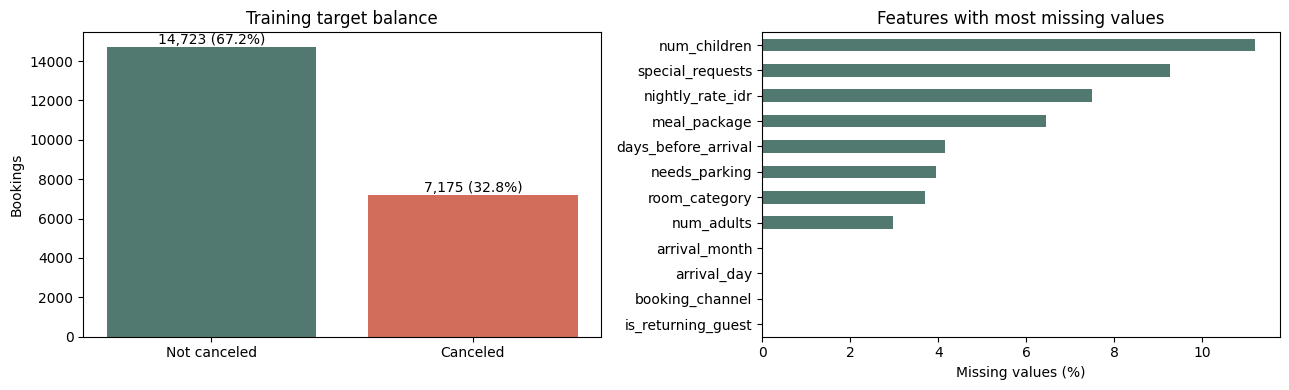

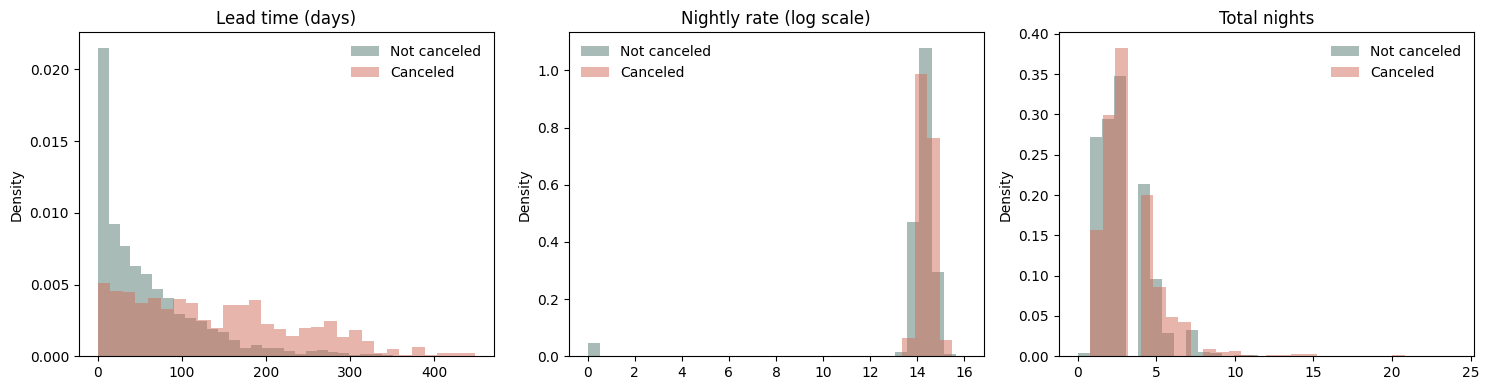

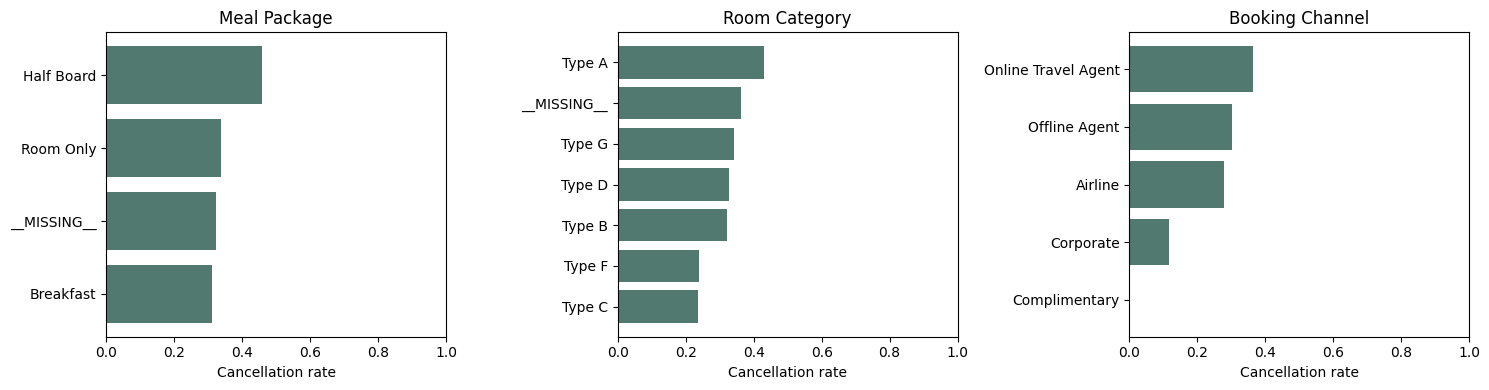

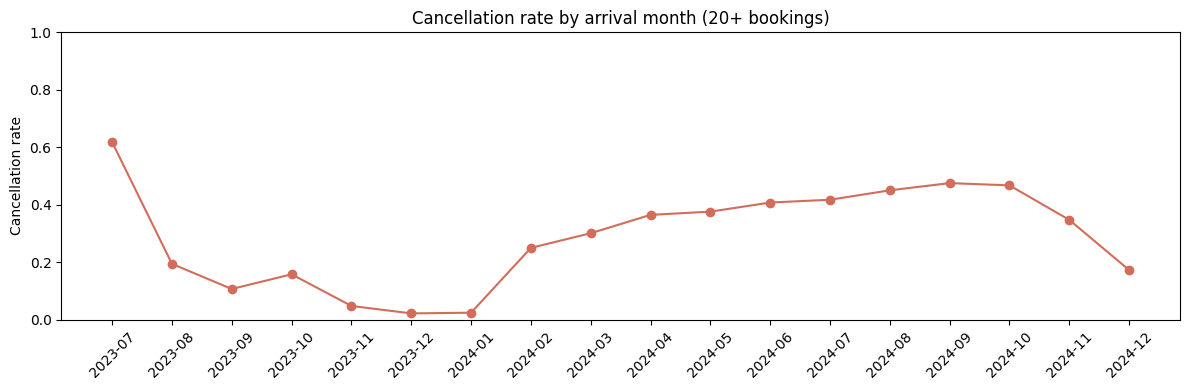

In [7]:
feature_columns = [
    column for column in train_df.columns
    if column not in {'id', 'is_canceled'}
]

# Target balance and missingness use training rows only.
target_counts = train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0)
missing_rates = train_set[feature_columns].isna().mean().mul(100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(
    ['Not canceled', 'Canceled'],
    target_counts,
    color=['#52796f', '#d16d5a'],
)
axes[0].set_title('Training target balance')
axes[0].set_ylabel('Bookings')
for index, count in enumerate(target_counts):
    axes[0].text(
        index, count, f'{count:,} ({count / len(train_set):.1%})',
        ha='center', va='bottom',
    )
missing_rates.tail(12).plot.barh(ax=axes[1], color='#52796f')
axes[1].set_title('Features with most missing values')
axes[1].set_xlabel('Missing values (%)')
fig.tight_layout()
plt.show()

# Compare numeric distributions by observed cancellation label.
distribution_features = {
    'Lead time (days)': train_set['days_before_arrival'],
    'Nightly rate (log scale)': np.log1p(
        train_set['nightly_rate_idr'].clip(lower=0)
    ),
    'Total nights': train_set['weekend_nights'] + train_set['weekday_nights'],
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (title, values) in zip(axes, distribution_features.items()):
    for label, color, name in (
        (0, '#52796f', 'Not canceled'),
        (1, '#d16d5a', 'Canceled'),
    ):
        observed = values[train_set['is_canceled'].eq(label)].dropna()
        axis.hist(
            observed, bins=30, density=True, alpha=0.5,
            color=color, label=name,
        )
    axis.set_title(title)
    axis.set_ylabel('Density')
    axis.legend(frameon=False)
fig.tight_layout()
plt.show()

# Hide unstable category rates with fewer than 30 examples.
categorical_features = train_set[feature_columns].select_dtypes(
    exclude='number'
).columns
fig, axes = plt.subplots(1, len(categorical_features), figsize=(15, 4))
for axis, column in zip(axes, categorical_features):
    grouped = train_set.assign(
        category=train_set[column].fillna('__MISSING__')
    ).groupby('category')['is_canceled'].agg(['size', 'mean'])
    grouped = grouped.loc[grouped['size'] >= 30].sort_values('mean')
    axis.barh(grouped.index.astype(str), grouped['mean'], color='#52796f')
    axis.set_title(column.replace('_', ' ').title())
    axis.set_xlim(0, 1)
    axis.set_xlabel('Cancellation rate')
fig.tight_layout()
plt.show()

# Target-aware monthly rates use training rows only.
monthly = train_set.assign(
    arrival_period=(
        train_set['arrival_year'].astype(str) + '-'
        + train_set['arrival_month'].astype(str).str.zfill(2)
    )
).groupby('arrival_period')['is_canceled'].agg(['size', 'mean'])
monthly = monthly.loc[monthly['size'] >= 20]
fig, axis = plt.subplots(figsize=(12, 4))
axis.plot(monthly.index, monthly['mean'], marker='o', color='#d16d5a')
axis.set_title('Cancellation rate by arrival month (20+ bookings)')
axis.set_ylabel('Cancellation rate')
axis.set_ylim(0, 1)
axis.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

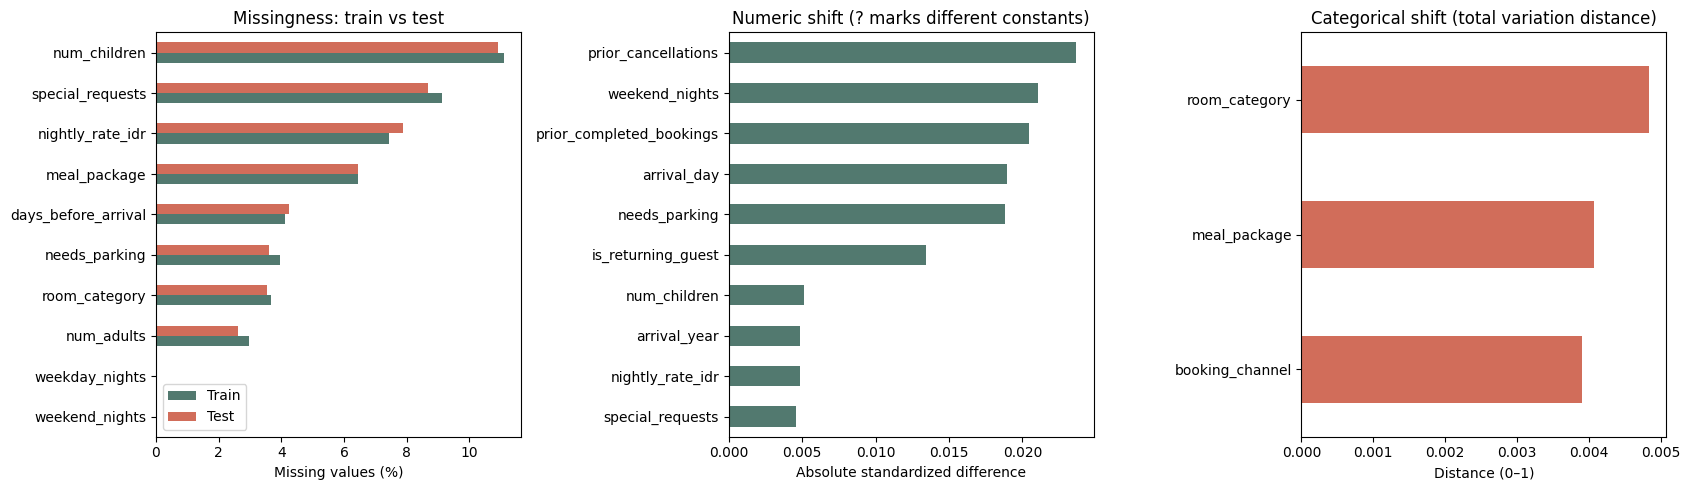

Drift charts are descriptive only; no target labels are used.


In [8]:
# Target-free train/test comparisons; target labels are intentionally excluded.
numeric_features = train_df[feature_columns].select_dtypes(include='number').columns
categorical_features = train_df[feature_columns].select_dtypes(
    exclude='number'
).columns

def standardized_mean_difference(train_values, test_values):
    train_values = pd.Series(train_values).dropna()
    test_values = pd.Series(test_values).dropna()
    if train_values.empty or test_values.empty:
        return np.nan

    pooled_scale = np.sqrt((train_values.std(ddof=0) ** 2 + test_values.std(ddof=0) ** 2) / 2)
    difference = abs(train_values.mean() - test_values.mean())
    if pooled_scale == 0:
        return np.inf if difference else 0.0
    return difference / pooled_scale


numeric_shift = {}
for column in numeric_features:
    numeric_shift[column] = standardized_mean_difference(
        train_df[column], test_df[column]
    )

categorical_shift = {}
for column in categorical_features:
    train_share = train_df[column].fillna('__MISSING__').value_counts(
        normalize=True
    )
    test_share = test_df[column].fillna('__MISSING__').value_counts(
        normalize=True
    )
    aligned = pd.concat([train_share, test_share], axis=1).fillna(0)
    categorical_shift[column] = (
        0.5 * (aligned.iloc[:, 0] - aligned.iloc[:, 1]).abs().sum()
    )

train_missing = train_df[feature_columns].isna().mean().mul(100)
test_missing = test_df[feature_columns].isna().mean().mul(100)
missing_features = (train_missing + test_missing).nlargest(10).index
missing_comparison = pd.DataFrame({
    'Train': train_missing[missing_features],
    'Test': test_missing[missing_features],
})

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
missing_comparison.sort_values('Train').plot.barh(
    ax=axes[0], color=['#52796f', '#d16d5a']
)
axes[0].set_title('Missingness: train vs test')
axes[0].set_xlabel('Missing values (%)')
top_numeric_shift = pd.Series(numeric_shift).dropna().nlargest(10)
finite_shift = top_numeric_shift[np.isfinite(top_numeric_shift)]
plot_cap = max(1.0, finite_shift.max() * 1.1) if len(finite_shift) else 1.0
plot_values = top_numeric_shift.replace(np.inf, plot_cap).sort_values()
if plot_values.empty:
    axes[1].text(0.5, 0.5, 'No overlapping values', ha='center', transform=axes[1].transAxes)
else:
    plot_values.plot.barh(ax=axes[1], color='#52796f')
    for row, column in enumerate(plot_values.index):
        if np.isinf(top_numeric_shift[column]):
            axes[1].text(plot_cap, row, '?', va='center')
axes[1].set_title('Numeric shift (? marks different constants)')
axes[1].set_xlabel('Absolute standardized difference')
pd.Series(categorical_shift).sort_values().plot.barh(
    ax=axes[2], color='#d16d5a'
)
axes[2].set_title('Categorical shift (total variation distance)')
axes[2].set_xlabel('Distance (0–1)')
fig.tight_layout()
plt.show()
print('Drift charts are descriptive only; no target labels are used.')

### Insight

Pada `train_set`, 7.175 dari 21.898 booking dibatalkan (32,8%); kelas 0 tetap lebih banyak daripada kelas 1. Median `days_before_arrival` pada booking canceled adalah 122 hari, dibandingkan 39 hari pada booking yang tidak canceled. Cancellation rate tercatat 36,3% pada `Online Travel Agent` dan 11,7% pada `Corporate`; menurut periode kedatangan, 2023-07 mencatat 61,8% dari 212 booking. Angka kategori dan periode ini bersifat deskriptif, bukan bukti sebab-akibat. Analisis berlabel memakai `train_set`; grafik drift train-test tidak menggunakan target.

## Verify Data Quality

Pemeriksaan menunjukkan nilai kosong pada beberapa fitur dan baris dengan fitur berulang. Nilai kosong tidak dihapus pada tahap ini. Pemeriksaan rentang dan kolom biner ditampilkan agar masalah kualitas data dapat ditangani pada tahap persiapan.

In [9]:
test_features = test_df.drop(columns='id')
binary_columns = ['needs_parking', 'is_returning_guest']
known_categories = {
    'meal_package': {'Room Only', 'Breakfast', 'Half Board', 'Full Board'},
    'room_category': {f'Type {letter}' for letter in 'ABCDEFG'},
    'booking_channel': {'Online Travel Agent', 'Offline Agent', 'Corporate', 'Airline', 'Complimentary'},
}
nonnegative_columns = ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
arrival_columns = ['arrival_year', 'arrival_month', 'arrival_day']
valid_arrival_dates = all(
    pd.to_datetime(frame[arrival_columns].rename(columns=dict(zip(arrival_columns, ['year', 'month', 'day']))), errors='coerce').notna().all()
    for frame in (train_set, test_features)
)
nonnegative_values = pd.concat([train_set[nonnegative_columns], test_features[nonnegative_columns]])
binary_values_valid = all(
    set(frame[column].dropna().unique()).issubset({0, 1})
    for frame in (train_set, test_features)
    for column in binary_columns
)
category_values_valid = all(
    set(frame[column].dropna().unique()).issubset(values)
    for frame in (train_set, test_features)
    for column, values in known_categories.items()
)
quality_checks = {
    'unique booking ids in train': train_set['id'].is_unique,
    'unique booking ids in test': test_df['id'].is_unique,
    'booking ids are present': train_set['id'].notna().all() and test_df['id'].notna().all(),
    'train and test ids are disjoint': set(train_set['id']).isdisjoint(test_df['id']),
    'train and test feature schemas match': set(feature_columns) == set(test_df.columns) - {'id'},
    'training target values are present and binary': train_set['is_canceled'].notna().all() and set(train_set['is_canceled'].unique()).issubset({0, 1}),
    'binary feature values in train and test': binary_values_valid,
    'known categorical values in train and test': category_values_valid,
    'arrival months between 1 and 12': train_set['arrival_month'].between(1, 12).all(),
    'arrival days between 1 and 31': train_set['arrival_day'].between(1, 31).all(),
    'valid arrival dates in train and test': valid_arrival_dates,
    'nonnegative counts and rates': (nonnegative_values.ge(0) | nonnegative_values.isna()).all().all(),
}
display(pd.Series(quality_checks, name='passed').to_frame())

duplicate_summary = pd.Series({
    'duplicate_full_train_rows': int(train_set.duplicated().sum()),
    'repeated_train_feature_rows': int(train_set.duplicated(subset=feature_columns, keep='first').sum()),
    'repeated_test_feature_rows': int(test_features.duplicated(subset=feature_columns, keep='first').sum()),
    'train_rows_with_duplicate_features': int(train_set.duplicated(subset=feature_columns, keep=False).sum()),
}, name='count').to_frame()
display(duplicate_summary)

duplicate_rows = train_set.loc[train_set.duplicated(subset=feature_columns, keep=False), feature_columns + ['is_canceled']]
conflicting_duplicate_groups = duplicate_rows.groupby(feature_columns, dropna=False, sort=False)['is_canceled'].nunique().gt(1).sum()
print(f'Duplicate feature groups with conflicting training labels: {conflicting_duplicate_groups}')

,passed
unique booking ids in train,True
unique booking ids in test,True
booking ids are present,True
train and test ids are disjoint,True
train and test feature schemas match,True
training target values are present and binary,True
binary feature values in train and test,True
known categorical values in train and test,True
arrival months between 1 and 12,True
arrival days between 1 and 31,True


,count
duplicate_full_train_rows,0
repeated_train_feature_rows,40
repeated_test_feature_rows,3
train_rows_with_duplicate_features,79


Duplicate feature groups with conflicting training labels: 0


### Insight

Seluruh 12 pemeriksaan kualitas pada train dan test lulus, termasuk kesesuaian schema, rentang nilai, dan keunikan `id`. Tidak ditemukan baris train yang identik pada semua kolom; terdapat 40 baris train dan 3 baris test yang mengulang kombinasi fitur, tanpa grup fitur dengan label train yang konflik. Missing values dan outlier dipertahankan untuk ditangani atau ditinjau pada tahap berikutnya.

---

# Training and Validation Split <a name="4"></a>

---

Split stratified dengan seed 42 menghasilkan 21.898 baris training dan 5.475 baris validation. Training split memuat 14.723 booking class 0 dan 7.175 class 1; validation memuat 3.681 class 0 dan 1.794 class 1. Ada 25 kombinasi fitur yang muncul di kedua split; baris tersebut dipertahankan dan tidak memakai `id` sebagai feature.

In [10]:
split_names = np.full(len(train_df), 'train', dtype=object)
split_names[valid_idx] = 'validation'
split_class_counts = pd.crosstab(
    pd.Series(split_names, name='split'),
    pd.Series(y, name='is_canceled'),
).reindex(columns=[0, 1], fill_value=0)
display(split_class_counts)

cross_split_duplicate_features = train_set[feature_columns].drop_duplicates().merge(
    val_set[feature_columns].drop_duplicates(), on=feature_columns, how='inner'
).shape[0]
print(f'Identical feature rows across train and validation: {cross_split_duplicate_features}')

is_canceled,0,1
split,,
train,14723,7175
validation,3681,1794


Identical feature rows across train and validation: 25


---

# Data Preparation <a name="5"></a>

---

Bagian ini merangkum kualitas dan bentuk data. Pipeline baseline di bagian berikut di-fit pada training split; pengembangan lanjutan dilakukan terpisah oleh tiap anggota.

Gunakan hasil pemeriksaan ini untuk memilih representasi baseline. Nilai statistik dan kategori dalam preprocessing tidak boleh dipelajari dari validation atau test.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [11]:
feature_columns = [column for column in train_df.columns if column not in {'id', 'is_canceled'}]
X_train_raw = train_df.iloc[train_idx][feature_columns].copy()
X_val_raw = train_df.iloc[valid_idx][feature_columns].copy()
X_test_raw = test_df[feature_columns].copy()
y_train = train_df.iloc[train_idx]['is_canceled'].to_numpy(dtype=int)
y_val = train_df.iloc[valid_idx]['is_canceled'].to_numpy(dtype=int)

if X_train_raw.columns.tolist() != X_val_raw.columns.tolist() or X_train_raw.columns.tolist() != X_test_raw.columns.tolist():
    raise ValueError('Train, validation, and test predictors must have the same columns in the same order.')
if {'id', 'is_canceled'} & set(feature_columns):
    raise ValueError('ID and target columns must not be model features.')

print(f'Features: {len(feature_columns)} | train: {len(X_train_raw)} | validation: {len(X_val_raw)} | test: {len(X_test_raw)}')
display(pd.DataFrame({'dtype': X_train_raw.dtypes.astype(str), 'missing_train': X_train_raw.isna().sum(), 'unique_train': X_train_raw.nunique(dropna=True)}))

Features: 17 | train: 21898 | validation: 5475 | test: 6844


,dtype,missing_train,unique_train
num_adults,float64,652,5
num_children,float64,2453,6
weekend_nights,int64,0,8
weekday_nights,int64,0,18
meal_package,object,1413,4
needs_parking,float64,865,2
room_category,object,811,7
days_before_arrival,float64,909,403
arrival_year,int64,0,2
arrival_month,int64,0,12


### Insight

`id` dan `is_canceled` tidak masuk ke prediktor. Train, validation, dan test memakai urutan 17 fitur yang sama.

## Clean Data

Bagian ini melaporkan kondisi data sebelum baseline preprocessing; imputasi dilakukan pada training split di bagian pipeline.

### Missing Values

This part covers missing values, if any.

In [12]:
missingness = pd.DataFrame({
    'train': X_train_raw.isna().sum(),
    'validation': X_val_raw.isna().sum(),
    'test': X_test_raw.isna().sum(),
})
missingness['train_pct'] = X_train_raw.isna().mean().mul(100).round(2)
display(missingness.loc[missingness[['train', 'validation', 'test']].any(axis=1)].sort_values('train', ascending=False))

,train,validation,test,train_pct
num_children,2453,582,747,11.20
special_requests,2029,471,593,9.27
nightly_rate_idr,1640,398,540,7.49
meal_package,1413,347,442,6.45
days_before_arrival,909,214,290,4.15
needs_parking,865,217,247,3.95
room_category,811,191,242,3.70
num_adults,652,157,180,2.98


### Insight

Sel ini hanya melaporkan missingness. Imputasi dipelajari nanti pada training fold atau `train_set`, tidak di sini.

### Duplicates

This part covers repeated records.

In [13]:
duplicate_mask = X_train_raw.duplicated(keep=False)
if duplicate_mask.any():
    duplicate_rows = X_train_raw.loc[duplicate_mask].copy()
    duplicate_rows['target'] = y_train[duplicate_mask.to_numpy()]
    duplicate_groups = duplicate_rows.groupby(feature_columns, dropna=False).agg(
        rows=('target', 'size'),
        distinct_labels=('target', 'nunique'),
    ).sort_values(['distinct_labels', 'rows'], ascending=False)
    display(duplicate_groups.head(20))
    print(f'Duplicate feature rows: {int(duplicate_mask.sum())}; groups with conflicting labels: {int((duplicate_groups["distinct_labels"] > 1).sum())}')
else:
    duplicate_groups = pd.DataFrame(columns=['rows', 'distinct_labels'])
    print('No duplicate feature rows in train_set.')

rows  \
num_adults num_children weekend_nights weekday_nights meal_package needs_parking room_category days_before_arrival arrival_year arrival_month arrival_day booking_channel     is_returning_guest prior_cancellations prior_completed_bookings nightly_rate_idr special_requests         
2.0        0.0          2              0              Half Board   0.0           Type B        388.0               2024         10            22          Offline Agent       0                  0                   0                        NaN              1.0                  3   
1.0        0.0          0              1              Breakfast    0.0           Type B        24.0                2023         10            29          Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                                                               95.0                2024         2             19          Corporate           0                  0                   0                        1339000.0        0.0                  2   
                                                                                 Type C        0.0                 2023         8             26          Online Travel Agent 0                  0                   0                        0.0              1.0                  2   
                                       2              Breakfast    0.0           Type B        162.0               2023         10            2           Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                                                               163.0               2023         10            2           Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                                                               182.0               2024         10            10          Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                                                               190.0               2024         6             23          Offline Agent       0                  0                   0                        1524000.0        0.0                  2   
                                                                                               194.0               2024         6             23          Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                      Half Board   0.0           Type B        6.0                 2023         12            10          Online Travel Agent 0                  0                   0                        0.0              0.0                  2   
                                       3              Breakfast    0.0           Type B        155.0               2024         1             19          Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                                                               164.0               2024         10            31          Offline Agent       0                  0                   0                        1763000.0        0.0                  2   
                                                                                               171.0               2024         10            31          Offline Agent       0                  0                   0                        NaN              0.0                  2   
                                                          

Duplicate feature rows: 79; groups with conflicting labels: 0


### Insight

Baris duplikat dan label yang konflik dilaporkan tanpa menghapus baris atau mengubah split.

### Outliers

This part covers values far from the rest of the data.

In [14]:
numeric_columns_raw = X_train_raw.select_dtypes(include='number').columns.tolist()
quantiles = X_train_raw[numeric_columns_raw].quantile([0.25, 0.75])
iqr = quantiles.loc[0.75] - quantiles.loc[0.25]
lower = quantiles.loc[0.25] - 1.5 * iqr
upper = quantiles.loc[0.75] + 1.5 * iqr
outlier_counts = ((X_train_raw[numeric_columns_raw] < lower) | (X_train_raw[numeric_columns_raw] > upper)).sum()
outlier_summary = pd.DataFrame({'iqr_outliers': outlier_counts, 'lower_bound': lower, 'upper_bound': upper})
display(outlier_summary.loc[outlier_summary['iqr_outliers'] > 0].sort_values('iqr_outliers', ascending=False))
print('Outliers are reported only; no rows are removed and no values are clipped.')

,iqr_outliers,lower_bound,upper_bound
num_adults,5850,2.0,2.0
arrival_year,3925,2024.0,2024.0
num_children,1626,0.0,0.0
nightly_rate_idr,924,314000.0,3042000.0
days_before_arrival,739,-146.5,289.5
needs_parking,637,0.0,0.0
is_returning_guest,546,0.0,0.0
prior_completed_bookings,476,0.0,0.0
special_requests,436,-1.5,2.5
weekday_nights,200,-2.0,6.0


Outliers are reported only; no rows are removed and no values are clipped.


### Insight

Batas IQR dipakai untuk diagnosis saja. Tidak ada outlier yang dihapus atau di-clip.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [15]:
numeric_data = X_train_raw[numeric_columns_raw]
nonnegative_columns = [column for column in numeric_columns_raw if column not in {'arrival_year', 'arrival_month', 'arrival_day'}]
checks = {
    'non-binary target': not np.isin(y_train, [0, 1]).all(),
    'negative count/price values': (numeric_data[nonnegative_columns].lt(0) & numeric_data[nonnegative_columns].notna()).any().any(),
    'arrival month outside 1..12': (numeric_data['arrival_month'].notna() & ~numeric_data['arrival_month'].between(1, 12)).any(),
    'arrival day outside 1..31': (numeric_data['arrival_day'].notna() & ~numeric_data['arrival_day'].between(1, 31)).any(),
}
quality_checks = pd.DataFrame({'issue_found': checks})
display(quality_checks)
if any(checks.values()):
    print('Review these values before modeling; no records are silently corrected.')
else:
    print('No invalid target, negative count/price, or out-of-range calendar values found in train_set.')

,issue_found
non-binary target,False
negative count/price values,False
arrival month outside 1..12,False
arrival day outside 1..31,False


No invalid target, negative count/price, or out-of-range calendar values found in train_set.


### Insight

Pemeriksaan menandai nilai di luar domain yang diharapkan; data tidak dikoreksi diam-diam.

## Construct Data

Baseline tidak memakai fitur turunan; tiap anggota dapat mengujinya di notebook improvement.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [16]:
print('No derived features in the baseline; try them in separate improvement notebooks.')

No derived features in the baseline; try them in separate improvement notebooks.


### Insight

Baseline tidak membuat fitur turunan; eksperimen fitur tambahan dilakukan di notebook improvement.

### Feature Scaling

Baseline numerik akan diimputasi dan distandardisasi; CART tetap memakai data raw untuk kategori, numerik, dan null.

In [17]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns.tolist()
categorical_columns = X_train_raw.select_dtypes(exclude='number').columns.tolist()
feature_types = pd.DataFrame({
    'feature_type': ['numeric'] * len(numeric_columns) + ['categorical'] * len(categorical_columns),
}, index=numeric_columns + categorical_columns)
display(feature_types)
print('Feature types shown before train-only baseline preprocessing.')

,feature_type
num_adults,numeric
num_children,numeric
weekend_nights,numeric
weekday_nights,numeric
needs_parking,numeric
days_before_arrival,numeric
arrival_year,numeric
arrival_month,numeric
arrival_day,numeric
is_returning_guest,numeric


Feature types shown before train-only baseline preprocessing.


### Insight

Baseline numerik diimputasi dan distandardisasi dengan statistik training split; CART menggunakan data asli.

### Encoding

Pilih encoding sesuai model dan implementasinya. CART dapat memakai jalur fitur raw jika model menangani kategori secara native.

In [18]:
encoding_summary = pd.DataFrame({
    'dtype': X_train_raw[categorical_columns].dtypes.astype(str),
    'categories_in_train': X_train_raw[categorical_columns].nunique(dropna=True),
    'missing_in_train': X_train_raw[categorical_columns].isna().sum(),
})
display(encoding_summary)
print('Baseline one-hot encoding is fitted on the training split in the pipeline section.')

,dtype,categories_in_train,missing_in_train
meal_package,object,4,1413
room_category,object,7,811
booking_channel,object,5,0


Baseline one-hot encoding is fitted on the training split in the pipeline section.


### Insight

Baseline numerik menggunakan one-hot encoding kategori dari training split; CART memisahkan kategori dan nilai null secara native.

### Dimensionality Reduction

Seleksi fitur atau reduksi dimensi bersifat opsional dan ditentukan per model dengan data training saja.

In [19]:
print('Baseline retains all features; further selection belongs in improvement notebooks.')

Baseline retains all features; further selection belongs in improvement notebooks.


### Insight

Baseline mempertahankan seluruh prediktor; pemilihan fitur lanjutan dikerjakan pada notebook improvement.

## Class Balance

Distribusi kelas ditampilkan sebagai informasi. Penanganan imbalance, jika diperlukan, dilakukan per model dan hanya pada training fold.

In [20]:
class_counts = pd.Series(y_train).value_counts().reindex([0, 1], fill_value=0)
class_balance = pd.DataFrame({'count': class_counts, 'proportion': class_counts / len(y_train)})
display(class_balance)
print('Baseline retains the natural training class distribution.')

,count,proportion
0,14723,0.672345
1,7175,0.327655


Baseline retains the natural training class distribution.


### Insight

Baseline tidak melakukan resampling. Penanganan ketidakseimbangan kelas merupakan bagian dari eksperimen improvement.

## Format Data

Notebook utama menyiapkan data mentah dan split bersama. Pipeline baseline menyiapkan matriks numerik serta jalur raw untuk CART.

In [21]:
raw_input_summary = pd.DataFrame({
    'rows': [len(X_train_raw), len(X_val_raw), len(X_test_raw)],
    'features': [X_train_raw.shape[1], X_val_raw.shape[1], X_test_raw.shape[1]],
    'missing_values': [int(X_train_raw.isna().sum().sum()), int(X_val_raw.isna().sum().sum()), int(X_test_raw.isna().sum().sum())],
}, index=['train', 'validation', 'test'])
display(raw_input_summary)
print('Baseline preprocessing is fitted on the training split in the next section.')

,rows,features,missing_values
train,21898,17,10772
validation,5475,17,2577
test,6844,17,3281


Baseline preprocessing is fitted on the training split in the next section.


### Insight

Tabel merangkum data mentah sebelum transformasi khusus baseline pada bagian berikut.

---

# Baseline Model Pipeline <a name="6"></a>

---

Baseline menggunakan satu representasi numerik untuk KNN, Logistic Regression, SVM, dan Gaussian Naive Bayes, serta input raw untuk CART. Semua transformasi yang mempelajari parameter hanya di-fit pada training split. Setiap anggota memakai [`Model_Pipeline_Template.ipynb`](Model_Pipeline_Template.ipynb) untuk eksperimen improvement independen.

In [22]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns.tolist()
categorical_columns = X_train_raw.select_dtypes(exclude='number').columns.tolist()


def make_baseline_preprocessor():
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('numeric', numeric_pipeline, numeric_columns),
        ('categorical', categorical_pipeline, categorical_columns),
    ], sparse_threshold=0)


baseline_preprocessor = make_baseline_preprocessor()
X_train_baseline = baseline_preprocessor.fit_transform(X_train_raw)
X_val_baseline = baseline_preprocessor.transform(X_val_raw)

if not np.isfinite(X_train_baseline).all() or not np.isfinite(X_val_baseline).all():
    raise ValueError('Preprocessing must produce finite numeric features.')

print(
    f'Baseline matrix: {X_train_baseline.shape}; '
    f'CART keeps {X_train_raw.shape[1]} original columns.'
)

Baseline matrix: (21898, 36); CART keeps 17 original columns.


---

# Modeling and Validation <a name="7"></a>

---

Target adalah `is_canceled`. Semua model inti dari nol didefinisikan pada sel algoritma masing-masing dengan NumPy/pandas; scikit-learn hanya dipakai untuk transformasi, metrik, dan pembanding. Konfigurasi baseline tetap, bukan hasil tuning validation.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

KNN memakai jarak Euclidean pada fitur numerik yang sudah distandardisasi dan kategori one-hot; voting seri memilih kelas 0.

In [23]:
class KNNBaseline:
    def __init__(self, k=7):
        self.k = k

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=int)
        if not 1 <= self.k <= len(self.y_):
            raise ValueError('k must be between 1 and the number of training rows')
        self.norms_ = np.sum(self.X_ ** 2, axis=1)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = []

        for start in range(0, len(X), 128):
            batch = X[start:start + 128]
            squared_distances = (
                np.sum(batch ** 2, axis=1)[:, None]
                + self.norms_[None, :]
                - 2 * batch @ self.X_.T
            )
            squared_distances = np.maximum(squared_distances, 0)
            neighbor_indices = np.argpartition(
                squared_distances, self.k - 1, axis=1
            )[:, :self.k]
            positive_votes = self.y_[neighbor_indices].sum(axis=1)
            predictions.extend((positive_votes > self.k / 2).astype(int))

        return np.asarray(predictions, dtype=int)


baseline_factories = {'knn': lambda: KNNBaseline(k=7)}
print(f'Seed: {CFG.SEED}')
print(f'NumPy: {np.__version__} | pandas: {pd.__version__}')
print(f'scikit-learn: {sklearn.__version__}')

Seed: 42
NumPy: 1.26.4 | pandas: 2.2.2
scikit-learn: 1.7.1


## Decision Tree Learning

CART memilih pemisahan Gini pada fitur numerik dan kategorikal asli, termasuk routing nilai null. Kedalaman dibatasi agar baseline tetap praktis.

In [24]:
class CARTBaseline:
    """Mixed-feature tree with gini, information-gain, or gain-ratio splits."""

    def __init__(
        self, max_depth=6, min_leaf=80, max_thresholds=16, criterion='gini'
    ):
        if criterion not in {'gini', 'information_gain', 'gain_ratio'}:
            raise ValueError('Unsupported decision-tree criterion')
        self.max_depth = max_depth
        self.min_leaf = min_leaf
        self.max_thresholds = max_thresholds
        self.criterion = criterion

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        self.columns_ = X.columns.tolist()
        self.numeric_ = {
            column: pd.api.types.is_numeric_dtype(X[column])
            for column in self.columns_
        }
        self.data_ = {column: X[column].to_numpy() for column in self.columns_}
        self.y_ = np.asarray(y, dtype=int)
        if len(X) != len(self.y_) or len(X) == 0:
            raise ValueError('Features and target must have equal, nonzero lengths')

        self.root_ = self._grow(np.arange(len(X)), depth=0)
        del self.data_, self.y_
        return self

    def _impurity(self, y):
        if not len(y):
            return 0.0
        if self.criterion == 'gini':
            positive_rate = np.mean(y)
            return 2 * positive_rate * (1 - positive_rate)
        probabilities = np.bincount(y, minlength=2) / len(y)
        probabilities = probabilities[probabilities > 0]
        return -np.sum(probabilities * np.log2(probabilities))

    def _score_split(self, parent, groups):
        sizes = np.array([len(group) for group in groups], dtype=float)
        if len(sizes) < 2 or np.any(sizes < self.min_leaf):
            return None
        proportions = sizes / sizes.sum()
        gain = self._impurity(parent) - sum(
            share * self._impurity(group)
            for share, group in zip(proportions, groups)
        )
        if gain <= 1e-12:
            return None
        if self.criterion == 'gain_ratio':
            split_info = -np.sum(proportions * np.log2(proportions))
            return gain / split_info if split_info else None
        return gain

    def _grow(self, indices, depth):
        y = self.y_[indices]
        node = {'label': int(np.sum(y) > len(y) / 2)}
        stop = (
            depth >= self.max_depth
            or len(indices) < 2 * self.min_leaf
            or np.all(y == y[0])
        )
        if stop:
            return node

        best_score = 0.0
        best_split = None
        for column in self.columns_:
            values = self.data_[column][indices]
            missing = pd.isna(values)
            observed = values[~missing]

            # ID3/C4.5 use multiway categorical splits; CART stays binary.
            if not self.numeric_[column] and self.criterion != 'gini':
                normalized = [None if pd.isna(value) else value for value in values]
                categories = list(dict.fromkeys(normalized))
                groups = {}
                for category in categories:
                    mask = np.fromiter(
                        (value == category for value in normalized),
                        dtype=bool,
                        count=len(values),
                    )
                    groups[category] = indices[mask]
                score = self._score_split(
                    y, [self.y_[child] for child in groups.values()]
                )
                if score is not None and score > best_score + 1e-12:
                    best_score = score
                    best_split = ('multiway', column, groups)
                continue

            if self.numeric_[column]:
                distinct = np.unique(observed.astype(float))
                if len(distinct) > self.max_thresholds + 1:
                    quantiles = np.linspace(0, 1, self.max_thresholds + 1)
                    distinct = np.unique(np.quantile(distinct, quantiles))
                candidates = [
                    (threshold, None, False)
                    for threshold in ((distinct[:-1] + distinct[1:]) / 2)
                ]
            else:
                candidates = [(None, category, False) for category in pd.unique(observed)]
            candidates.append((None, None, True))

            for threshold, category, missing_only in candidates:
                if missing_only:
                    selected = missing
                elif threshold is not None:
                    selected = values <= threshold
                else:
                    selected = values == category

                route_missing = not missing_only and missing.any()
                missing_options = (False, True) if route_missing else (False,)
                for missing_left in missing_options:
                    left = selected | missing if missing_left else selected
                    if missing_only:
                        left = missing
                    groups = [y[left], y[~left]]
                    score = self._score_split(y, groups)
                    if score is not None and score > best_score + 1e-12:
                        best_score = score
                        best_split = (
                            'binary', column, threshold, category,
                            missing_left, missing_only, indices[left], indices[~left],
                        )

        if best_split is None:
            return node
        if best_split[0] == 'multiway':
            _, column, groups = best_split
            node.update(
                split_kind='multiway',
                column=column,
                branches={
                    category: self._grow(child, depth + 1)
                    for category, child in groups.items()
                },
            )
        else:
            _, column, threshold, category, missing_left, missing_only, left, right = best_split
            node.update(
                split_kind='binary',
                column=column,
                threshold=threshold,
                category=category,
                missing_left=missing_left,
                missing_only=missing_only,
                left=self._grow(left, depth + 1),
                right=self._grow(right, depth + 1),
            )
        return node

    def predict(self, X):
        X = pd.DataFrame(X)[self.columns_]
        predictions = []
        for row in X.itertuples(index=False, name=None):
            values = dict(zip(self.columns_, row))
            node = self.root_
            while 'split_kind' in node:
                column = node['column']
                value = values[column]
                if node['split_kind'] == 'multiway':
                    category = None if pd.isna(value) else value
                    if category not in node['branches']:
                        break
                    node = node['branches'][category]
                    continue

                if pd.isna(value):
                    go_left = node['missing_left'] or node['missing_only']
                elif node['missing_only']:
                    go_left = False
                elif node['threshold'] is not None:
                    go_left = value <= node['threshold']
                else:
                    go_left = value == node['category']
                node = node['left' if go_left else 'right']
            predictions.append(node['label'])
        return np.asarray(predictions, dtype=int)


baseline_factories.update({
    'dtl_id3': lambda: CARTBaseline(
        max_depth=6, min_leaf=80, criterion='information_gain'
    ),
    'dtl_c45': lambda: CARTBaseline(
        max_depth=6, min_leaf=80, criterion='gain_ratio'
    ),
    'dtl_cart': lambda: CARTBaseline(
        max_depth=6, min_leaf=80, criterion='gini'
    ),
})

## Logistic Regression

Tiga regularisasi dilatih dengan gradien log-loss dan proximal step untuk komponen L1. Semua memakai fitur yang sama.

In [25]:
class LogisticBaseline:
    def __init__(self, penalty='l2', alpha=0.01, l1_ratio=0.5, lr=0.1, epochs=250):
        if penalty not in ('l1', 'l2', 'elasticnet'):
            raise ValueError('Unsupported penalty')
        self.penalty = penalty
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.weights_ = np.zeros(X.shape[1])
        self.bias_ = 0.0

        l1_ratio = self.l1_ratio if self.penalty == 'elasticnet' else 1
        l2_ratio = 1 - self.l1_ratio if self.penalty == 'elasticnet' else 1
        l1_strength = self.alpha * l1_ratio if self.penalty != 'l2' else 0
        l2_strength = self.alpha * l2_ratio if self.penalty != 'l1' else 0

        for _ in range(self.epochs):
            logits = np.clip(X @ self.weights_ + self.bias_, -30, 30)
            probabilities = 1 / (1 + np.exp(-logits))
            error = probabilities - y

            gradient = X.T @ error / len(y) + l2_strength * self.weights_
            weights = self.weights_ - self.lr * gradient
            self.weights_ = np.sign(weights) * np.maximum(
                np.abs(weights) - self.lr * l1_strength, 0
            )
            self.bias_ -= self.lr * error.mean()

        return self

    def predict(self, X):
        scores = np.asarray(X, dtype=float) @ self.weights_ + self.bias_
        return (scores >= 0).astype(int)


baseline_factories.update({
    'logistic_l1': lambda: LogisticBaseline(penalty='l1', alpha=0.01),
    'logistic_l2': lambda: LogisticBaseline(penalty='l2', alpha=0.01),
    'logistic_elasticnet': lambda: LogisticBaseline(
        penalty='elasticnet', alpha=0.01, l1_ratio=0.5
    ),
})

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

SVM meminimalkan hinge loss dengan regularisasi L2. Kernel polinomial dan Gaussian menggunakan 96 landmark tetap sebagai pendekatan fitur kernel, bukan solusi dual eksak; pembanding scikit-learn memakai kernel eksak.

In [26]:
class SVMBaseline:
    """Primal hinge-loss SVM over explicit kernel features."""

    def __init__(
        self, kernel='linear', alpha=0.01, degree=2, gamma=None,
        lr=0.1, epochs=80, landmarks=96,
    ):
        if kernel not in ('linear', 'poly', 'rbf'):
            raise ValueError('Unsupported kernel')
        self.kernel = kernel
        self.alpha = alpha
        self.degree = degree
        self.gamma = gamma
        self.lr = lr
        self.epochs = epochs
        self.landmarks = landmarks

    def _features(self, X):
        X = np.asarray(X, dtype=float)
        if self.kernel == 'linear':
            return X

        dot_products = X @ self.landmarks_.T
        if self.kernel == 'poly':
            return (1 + self.gamma_ * dot_products) ** self.degree / self.scale_

        squared_distances = (
            np.sum(X ** 2, axis=1)[:, None]
            + self.landmark_norms_[None, :]
            - 2 * dot_products
        )
        squared_distances = np.maximum(squared_distances, 0)
        return np.exp(-self.gamma_ * squared_distances)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = 2 * np.asarray(y, dtype=int) - 1
        self.gamma_ = self.gamma if self.gamma is not None else 1 / X.shape[1]

        if self.kernel != 'linear':
            # shortcut: fixed landmarks approximate full kernels.
            # Use a dual solver when exact optimization is required.
            indices = np.linspace(
                0, len(X) - 1, min(self.landmarks, len(X)), dtype=int
            )
            self.landmarks_ = X[indices].copy()
            self.landmark_norms_ = np.sum(self.landmarks_ ** 2, axis=1)
            max_dot = np.max(np.abs(X @ self.landmarks_.T))
            self.scale_ = max(1.0, (1 + self.gamma_ * max_dot) ** self.degree)

        features = self._features(X)
        self.weights_ = np.zeros(features.shape[1])
        self.bias_ = 0.0

        for epoch in range(self.epochs):
            learning_rate = self.lr / (1 + epoch * 0.02)
            for start in range(0, len(y), 512):
                batch = features[start:start + 512]
                labels = y[start:start + 512]
                active = labels * (batch @ self.weights_ + self.bias_) < 1
                weight_gradient = (
                    self.alpha * self.weights_
                    - (batch[active].T @ labels[active]) / len(batch)
                )
                self.weights_ -= learning_rate * weight_gradient
                self.bias_ += learning_rate * labels[active].sum() / len(batch)

        return self

    def predict(self, X):
        scores = self._features(X) @ self.weights_ + self.bias_
        return (scores >= 0).astype(int)


baseline_factories.update({
    'svm_linear': lambda: SVMBaseline(kernel='linear'),
    'svm_poly': lambda: SVMBaseline(kernel='poly', degree=2),
    'svm_rbf': lambda: SVMBaseline(kernel='rbf'),
})

## Naive Bayes

Gaussian Naive Bayes memakai prior dan likelihood Gaussian per kelas dengan batas bawah varians agar fitur konstan tetap aman.

In [27]:
class GaussianNBBaseline:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.means_ = np.array([X[y == label].mean(axis=0) for label in (0, 1)])
        self.variances_ = np.array([X[y == label].var(axis=0) for label in (0, 1)])
        self.variances_ = np.maximum(self.variances_, 1e-6)
        self.priors_ = np.array([(y == label).mean() for label in (0, 1)])

        if np.any(self.priors_ == 0):
            raise ValueError('Both classes are required for Gaussian Naive Bayes')
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        log_likelihood = (
            np.log(2 * np.pi * self.variances_)[None, :, :]
            + (X[:, None, :] - self.means_[None, :, :]) ** 2
            / self.variances_[None, :, :]
        )
        log_posterior = np.log(self.priors_)[None, :] - 0.5 * np.sum(
            log_likelihood, axis=2
        )
        return np.argmax(log_posterior, axis=1).astype(int)


baseline_factories['gaussian_nb'] = lambda: GaussianNBBaseline()

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

Setiap varian dinilai pada `valid_idx` yang sama. Tabel utama menampilkan Macro F1 dan metrik per kelas; seri dipecahkan berdasarkan nama varian leksikografis. `dtl_cart` menjadi baseline scratch terbaik dengan Macro F1 0,7957.

In [28]:
def validation_metrics(y_true, predictions):
    predictions = np.asarray(predictions)
    if predictions.shape != y_true.shape or not np.isin(predictions, [0, 1]).all():
        raise ValueError('One binary prediction is required per validation row.')

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, predictions, labels=[0, 1], zero_division=0
    )
    macro_f1 = f1_score(
        y_true, predictions, labels=[0, 1], average='macro', zero_division=0
    )
    return {
        'macro_f1': macro_f1,
        'precision_0': precision[0],
        'precision_1': precision[1],
        'recall_0': recall[0],
        'recall_1': recall[1],
        'f1_0': f1[0],
        'f1_1': f1[1],
        'support_0': support[0],
        'support_1': support[1],
    }


scratch_results = []
validation_predictions = {}
scratch_confusions = {}
with threadpool_limits(limits=2):
    for name, build_model in baseline_factories.items():
        model = build_model()
        X_train = X_train_raw if name.startswith('dtl_') else X_train_baseline
        X_valid = X_val_raw if name.startswith('dtl_') else X_val_baseline
        model.fit(X_train, y_train)
        predictions = model.predict(X_valid)

        validation_predictions[name] = predictions
        scratch_confusions[name] = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        )
        scratch_results.append({
            'variant': name,
            **validation_metrics(y_val, predictions),
        })

scratch_scores = pd.DataFrame(scratch_results).set_index('variant')
scratch_scores = scratch_scores.sort_index().sort_values(
    'macro_f1', ascending=False, kind='stable'
)
winner_name = scratch_scores.index[0]
display(scratch_scores)
print(
    f'Baseline winner: {winner_name} '
    f'(Macro F1 = {scratch_scores.loc[winner_name, "macro_f1"]:.4f})'
)

,macro_f1,precision_0,precision_1,recall_0,recall_1,f1_0,f1_1,support_0,support_1
variant,,,,,,,,,
dtl_cart,0.795697,0.857218,0.745682,0.883999,0.697882,0.870403,0.720990,3681,1794
knn,0.780135,0.840956,0.742262,0.889161,0.654961,0.864387,0.695884,3681,1794
dtl_id3,0.771700,0.834312,0.734917,0.887802,0.638239,0.860226,0.683174,3681,1794
svm_linear,0.750770,0.809340,0.758516,0.913339,0.558528,0.858200,0.643339,3681,1794
logistic_l2,0.742172,0.802619,0.756863,0.915784,0.537904,0.855475,0.628869,3681,1794
logistic_elasticnet,0.740543,0.800000,0.765992,0.921489,0.527313,0.856458,0.624629,3681,1794
logistic_l1,0.737909,0.797285,0.771405,0.925292,0.517280,0.856532,0.619286,3681,1794
dtl_c45,0.698261,0.766695,0.853541,0.966857,0.396321,0.855220,0.541302,3681,1794
svm_rbf,0.659976,0.749256,0.798440,0.957892,0.342252,0.840825,0.479126,3681,1794


Baseline winner: dtl_cart (Macro F1 = 0.7957)


## Improvements (Optional)

Tuning, validasi silang, fitur baru, dan optimasi pipeline dilakukan dalam notebook final tiap model; hasilnya tidak mengubah baseline di notebook utama.

- **k-NN:** [`KNN_Final-Pipeline.ipynb`](KNN_Final-Pipeline.ipynb)
- **Decision Tree Learning (DTL):** [`DTL_Final-Pipeline.ipynb`](DTL_Final-Pipeline.ipynb)
- **Logistic Regression:** [`Logistic_Regression_Final-Pipeline.ipynb`](Logistic_Regression_Final-Pipeline.ipynb)
- **Support Vector Machine (SVM):** [`SVM_Final-Pipeline.ipynb`](SVM_Final-Pipeline.ipynb)
- **Naive Bayes:** [`Naive_Bayes_Final-Pipeline.ipynb`](Naive_Bayes_Final-Pipeline.ipynb)

In [29]:
print('Improvement pipelines are maintained in separate copies of Model_Pipeline_Template.ipynb.')

Improvement pipelines are maintained in separate copies of Model_Pipeline_Template.ipynb.


---

# Comparison with scikit-learn <a name="8"></a>

---

Pembanding memakai split dan evaluasi yang sama, tetapi representasi fiturnya tidak selalu sama. CART scratch memakai fitur raw, sedangkan CART `scikit-learn` memakai fitur one-hot encoded karena implementasi tersebut tidak menerima kategori dan null secara langsung. Pada validation set, Macro F1 terbaik adalah 0,7957 untuk scratch `dtl_cart`; pembanding terbaik adalah `dtl_cart` (0,7922), diikuti `svm_rbf` (0,7877). Perbedaan implementasi membatasi perbandingan langsung: SVM polinomial/Gaussian pembanding memakai kernel eksak, sementara scratch memakai aproksimasi landmark.

Pembanding scikit-learn memakai split biner: entropy untuk ID3/C4.5 dan Gini untuk CART. Karena tidak menyediakan split multiway ID3 atau gain-ratio C4.5 secara native, hasil tree tersebut adalah pendekatan, bukan implementasi yang identik.

In [30]:
comparison_factories = {
    'knn': lambda: KNeighborsClassifier(n_neighbors=7),
    'dtl_id3': lambda: DecisionTreeClassifier(
        criterion='entropy', max_depth=6, min_samples_leaf=80,
        random_state=CFG.SEED,
    ),
    'dtl_c45': lambda: DecisionTreeClassifier(
        criterion='entropy', max_depth=6, min_samples_leaf=80,
        random_state=CFG.SEED,
    ),
    'dtl_cart': lambda: DecisionTreeClassifier(
        criterion='gini', max_depth=6, min_samples_leaf=80,
        random_state=CFG.SEED,
    ),
    'logistic_l1': lambda: LogisticRegression(
        penalty='l1', C=1 / (0.01 * len(y_train)), solver='liblinear',
        max_iter=300, random_state=CFG.SEED,
    ),
    'logistic_l2': lambda: LogisticRegression(
        penalty='l2', C=1 / (0.01 * len(y_train)), solver='liblinear',
        max_iter=300, random_state=CFG.SEED,
    ),
    'logistic_elasticnet': lambda: LogisticRegression(
        penalty='elasticnet', l1_ratio=0.5, C=1 / (0.01 * len(y_train)),
        solver='saga', max_iter=300, random_state=CFG.SEED,
    ),
    'svm_linear': lambda: SVC(kernel='linear', C=1.0),
    'svm_poly': lambda: SVC(kernel='poly', degree=2, C=1.0),
    'svm_rbf': lambda: SVC(kernel='rbf', C=1.0),
    'gaussian_nb': lambda: GaussianNB(),
}

comparison_results = []
comparison_confusions = {}
with threadpool_limits(limits=2):
    for name, build_model in comparison_factories.items():
        comparator = build_model()
        comparator.fit(X_train_baseline, y_train)
        predictions = comparator.predict(X_val_baseline)
        comparison_confusions[name] = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        )
        comparison_results.append({
            'variant': name,
            **validation_metrics(y_val, predictions),
        })

comparison_scores = pd.DataFrame(comparison_results).set_index('variant')
comparison_summary = scratch_scores[['macro_f1']].rename(
    columns={'macro_f1': 'scratch_macro_f1'}
).join(
    comparison_scores[['macro_f1']].rename(
        columns={'macro_f1': 'sklearn_macro_f1'}
    )
)
display(comparison_summary)
display(comparison_scores)

,scratch_macro_f1,sklearn_macro_f1
variant,,
dtl_cart,0.795697,0.792194
knn,0.780135,0.780135
dtl_id3,0.771700,0.787542
svm_linear,0.750770,0.755458
logistic_l2,0.742172,0.753659
logistic_elasticnet,0.740543,0.747588
logistic_l1,0.737909,0.751218
dtl_c45,0.698261,0.787542
svm_rbf,0.659976,0.787699


,macro_f1,precision_0,precision_1,recall_0,recall_1,f1_0,f1_1,support_0,support_1
variant,,,,,,,,,
knn,0.780135,0.840956,0.742262,0.889161,0.654961,0.864387,0.695884,3681,1794
dtl_id3,0.787542,0.841998,0.764360,0.901929,0.652731,0.870934,0.704149,3681,1794
dtl_c45,0.787542,0.841998,0.764360,0.901929,0.652731,0.870934,0.704149,3681,1794
dtl_cart,0.792194,0.849651,0.755611,0.893507,0.675585,0.871028,0.713361,3681,1794
logistic_l1,0.751218,0.809581,0.759273,0.913610,0.559086,0.858456,0.643981,3681,1794
logistic_l2,0.753659,0.813246,0.750731,0.907362,0.572464,0.857730,0.649589,3681,1794
logistic_elasticnet,0.747588,0.807157,0.755912,0.913067,0.552397,0.856851,0.638325,3681,1794
svm_linear,0.755458,0.815005,0.749819,0.906004,0.578038,0.858099,0.652817,3681,1794
svm_poly,0.772694,0.823558,0.782577,0.919315,0.595875,0.868806,0.676582,3681,1794


---

# Saving and Loading Models <a name="9"></a>

---

Simpan hanya baseline scratch terbaik beserta state preprocessing-nya pada `output/final/model/`. Muat kembali hanya artefak tepercaya yang baru dibuat oleh notebook ini.

In [31]:
from joblib import dump, load

X_full_raw = train_df[feature_columns].copy()
y_full = train_df['is_canceled'].to_numpy(dtype=int)
final_preprocessor = None
if not winner_name.startswith('dtl_'):
    final_preprocessor = make_baseline_preprocessor()
    X_full_model = final_preprocessor.fit_transform(X_full_raw)
else:
    X_full_model = X_full_raw

with threadpool_limits(limits=2):
    final_model = baseline_factories[winner_name]().fit(X_full_model, y_full)

model_dir = CFG.OUTPUT_DIR / 'final' / 'model' / winner_name
model_dir.mkdir(parents=True, exist_ok=True)
artifact_path = model_dir / 'baseline.joblib'
model_bundle = {
    'variant': winner_name,
    'columns': feature_columns,
    'preprocessor': final_preprocessor,
    'model_state': final_model.__dict__,
}
dump(model_bundle, artifact_path)

# Only load the artifact written above, not arbitrary third-party pickle/joblib files.
restored = load(artifact_path)
if restored['variant'] != winner_name or restored['columns'] != feature_columns:
    raise ValueError('Loaded model metadata does not match the selected baseline.')
restored_model = baseline_factories[restored['variant']]()
restored_model.__dict__.update(restored['model_state'])
restored['model'] = restored_model

check_raw = X_full_raw.head(10)
if final_preprocessor is None:
    check_features = check_raw
    loaded_features = check_raw
else:
    check_features = final_preprocessor.transform(check_raw)
    loaded_features = restored['preprocessor'].transform(check_raw)

original_predictions = final_model.predict(check_features)
restored_predictions = restored['model'].predict(loaded_features)
if not np.array_equal(original_predictions, restored_predictions):
    raise ValueError('Loaded model predictions differ from the in-memory model.')
print(f'Saved and loaded {winner_name}: {artifact_path}')

Saved and loaded dtl_cart: c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\output\final\model\dtl_cart\baseline.joblib


---

# Kaggle Submission <a name="10"></a>

---

Pipeline pemenang telah di-fit ulang pada seluruh training CSV; test hanya ditransformasi. Submission mempertahankan `id` sesuai urutan `test.csv`.

In [32]:
if restored['preprocessor'] is None:
    X_test_final = X_test_raw
else:
    X_test_final = restored['preprocessor'].transform(X_test_raw)

with threadpool_limits(limits=2):
    test_predictions = np.asarray(restored['model'].predict(X_test_final))
if test_predictions.shape != (len(test_df),) or not np.isin(test_predictions, [0, 1]).all():
    raise ValueError('Expected one binary prediction per test row.')

submission = pd.DataFrame({
    'id': test_df['id'].to_numpy(),
    'is_canceled': test_predictions.astype(int),
})
expected_ids = test_df['id'].reset_index(drop=True)
if submission.columns.tolist() != ['id', 'is_canceled']:
    raise ValueError('Submission columns do not match the expected schema.')
if not submission['id'].equals(expected_ids):
    raise ValueError('Submission IDs or row order differ from test.csv.')

submission_path = CFG.OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print(f'Wrote {len(submission)} rows to {submission_path}')

Wrote 6844 rows to c:\Users\aufar\Institut Teknologi Bandung\IF3170_G03_FiveAgents\output\submission.csv


---

# Error Analysis <a name="11"></a>

---

Error Analysis hanya memakai `validation set` dan prediksi baseline yang telah dihitung. Analisis membedakan false positive (booking diprediksi canceled padahal tidak) dan false negative (booking canceled yang luput), lalu membandingkan error rate pada subgroup dengan support minimal 30. Baseline hanya menghasilkan hard labels; analisis confidence/probability dan threshold tidak tersedia.

Pada validation set, `dtl_cart` menghasilkan error rate 17,7% (969 dari 5.475 booking). False negative (542) lebih banyak daripada false positive (427); recall class 1 sebesar 69,8%, lebih rendah daripada recall class 0 sebesar 88,4%. Error rate tertinggi di antara subgroup yang memenuhi batas support muncul pada `arrival_month=3` (31,2%, n=343). Booking dengan 3+ missing features memiliki error rate 28,8%, dibandingkan 16,9% pada booking tanpa missing feature.

Error rate pada baris yang diprediksi berbeda oleh model mencapai 19,0%, dibandingkan 4,5% pada baris yang seluruh model sepakati. Perbedaan subgroup ini bersifat deskriptif, bukan kausal; hasilnya dapat membantu menentukan pemeriksaan fitur atau eksperimen lanjutan. Tidak ada label test yang digunakan.

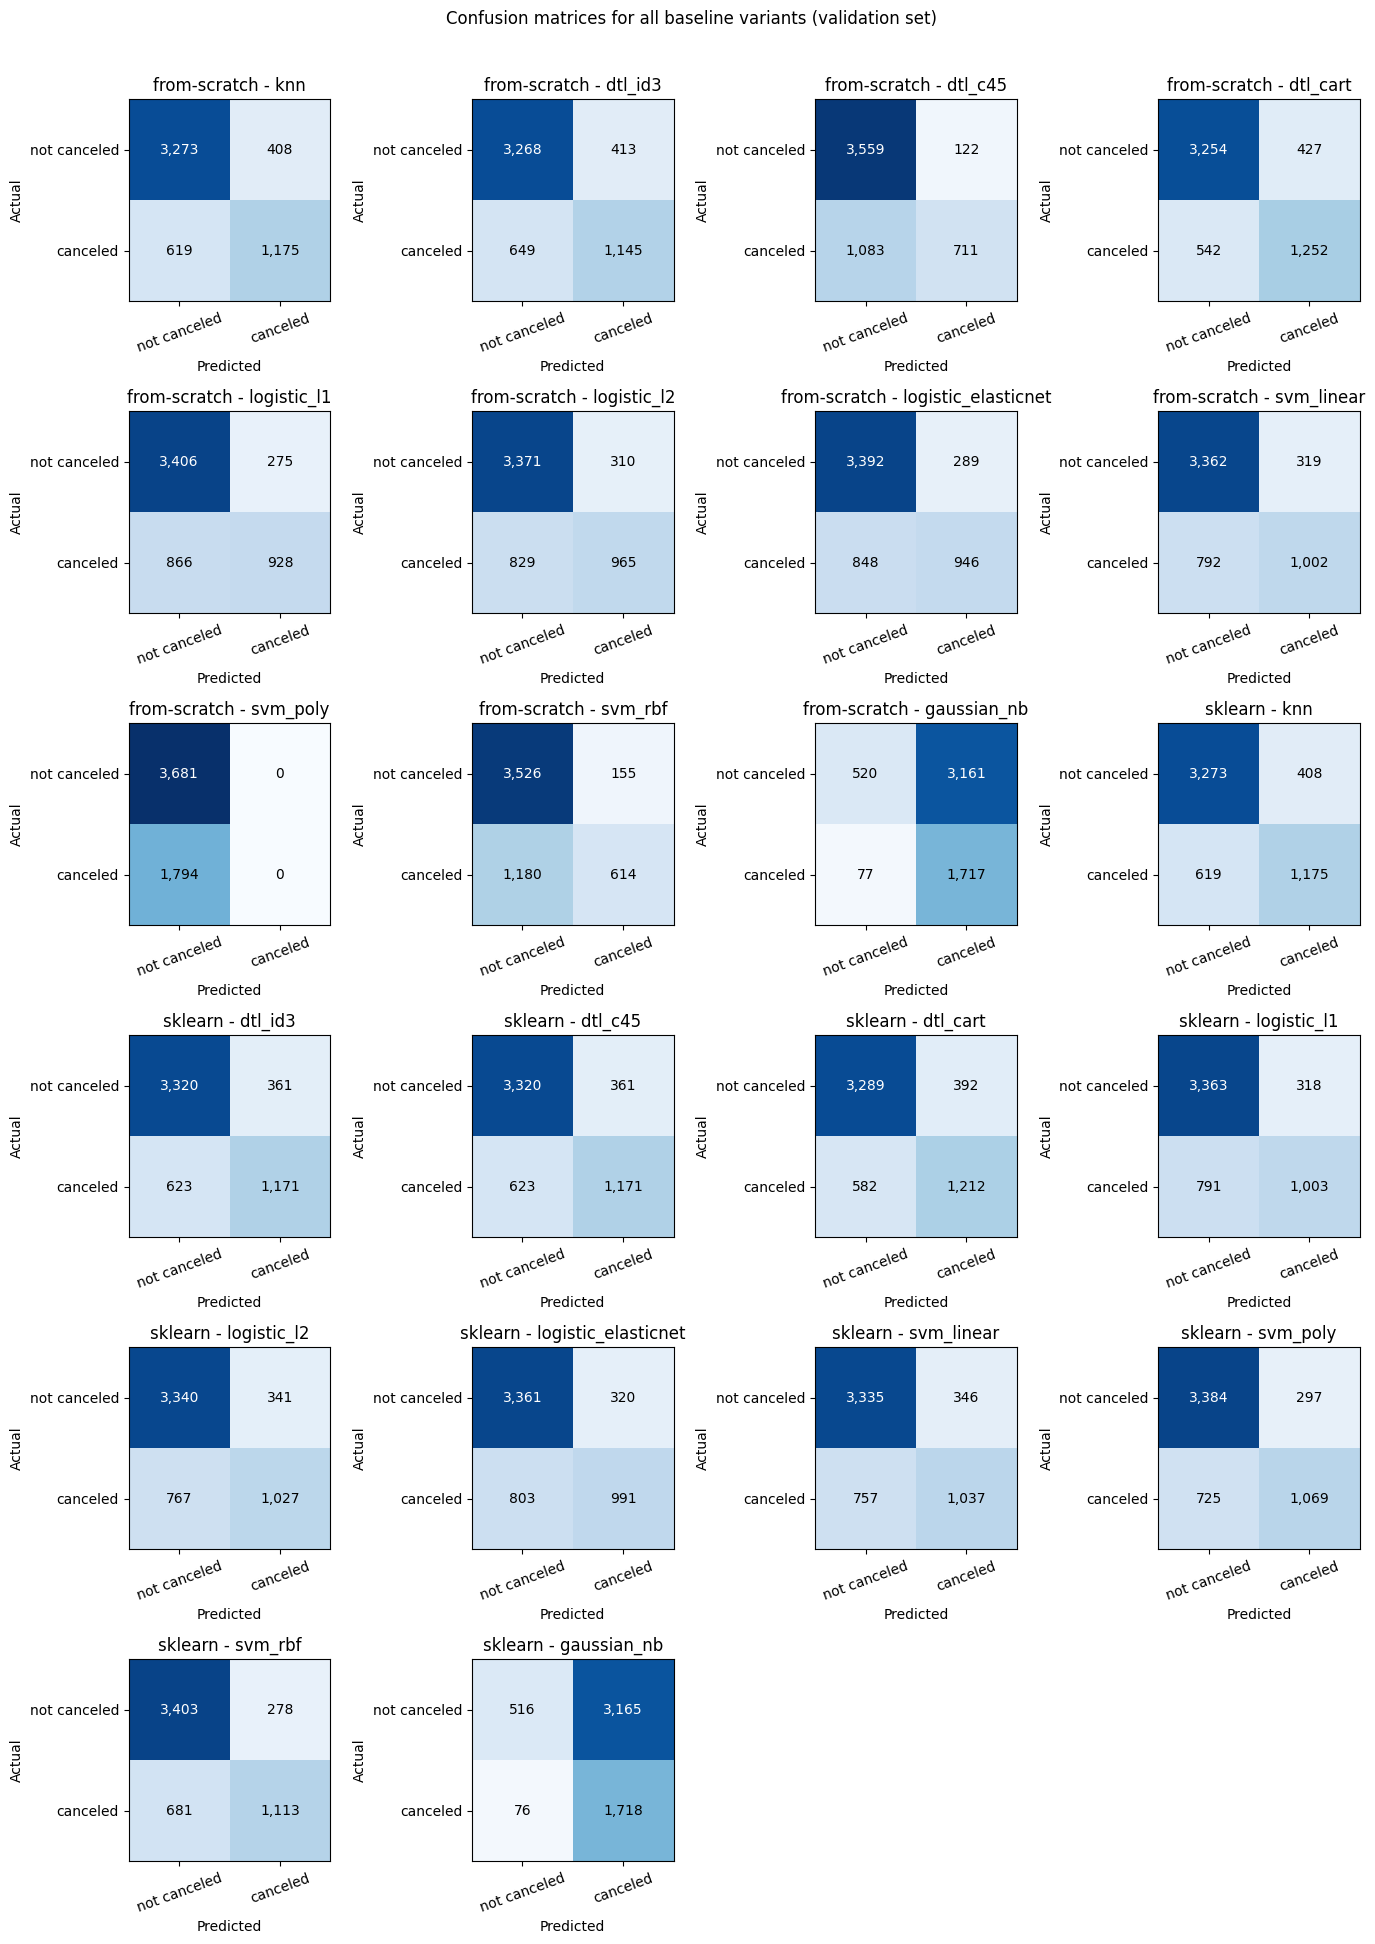

,count,share_of_validation
error_type,,
correct,4506,0.823014
false_positive,427,0.077991
false_negative,542,0.098995


,macro_f1,precision_0,precision_1,recall_0,recall_1,f1_0,f1_1,support_0,support_1
dtl_cart,0.795697,0.857218,0.745682,0.883999,0.697882,0.870403,0.72099,3681,1794


,support,errors,error_rate
model_disagreement,,,
model_agreement,494,22,0.044534
model_disagreement,4981,947,0.190122


Validation error slices: booking_channel (groups with support >= 30)


,support,errors,false_positive,false_negative,error_rate
booking_channel,,,,,
Online Travel Agent,3475,688,352,336,0.197986
Offline Agent,1603,238,68,170,0.148472
Corporate,324,35,5,30,0.108025
Complimentary,60,2,2,0,0.033333


Validation error slices: meal_package (groups with support >= 30)


... (7 outputs left out)

Validation error slices: lead_time_band (groups with support >= 30)


,support,errors,false_positive,false_negative,error_rate
lead_time_band,,,,,
"(58.0, 127.0]",1311,318,165,153,0.242563
"(127.0, 448.0]",1308,217,91,126,0.165902
"(16.0, 58.0]",1319,216,120,96,0.163760
"(-0.001, 16.0]",1323,165,33,132,0.124717


,days_before_arrival,nightly_rate_idr,special_requests,num_children
error_type,,,,
correct,53.0,1650000.0,1.0,0.0
false_negative,71.0,1644000.0,1.0,0.0
false_positive,79.0,1577500.0,0.0,0.0


,id,actual,predicted,error_type,days_before_arrival,booking_channel,meal_package,room_category,missing_feature_count,model_disagreement
20135,2cce4408,1,0,false_negative,390.0,Offline Agent,Half Board,Type B,2,True
18560,356a42c3,1,0,false_negative,389.0,Offline Agent,Half Board,Type B,0,True
25909,07fa822f,1,0,false_negative,386.0,Offline Agent,NaN,Type B,2,True
1720,18419c90,0,1,false_positive,383.0,Complimentary,Half Board,Type B,1,True
5396,3e7a5bd2,1,0,false_negative,382.0,Offline Agent,Half Board,Type B,1,True
18396,684bf447,1,0,false_negative,344.0,Offline Agent,Breakfast,Type B,0,True
20331,4ad83649,1,0,false_negative,344.0,Offline Agent,Half Board,Type B,0,True
2338,d59e2d53,0,1,false_positive,335.0,Offline Agent,Breakfast,Type B,0,True
4750,8c936e67,0,1,false_positive,332.0,Offline Agent,NaN,Type B,2,True
24786,026f5e27,0,1,false_positive,322.0,Offline Agent,Breakfast,Type B,1,True


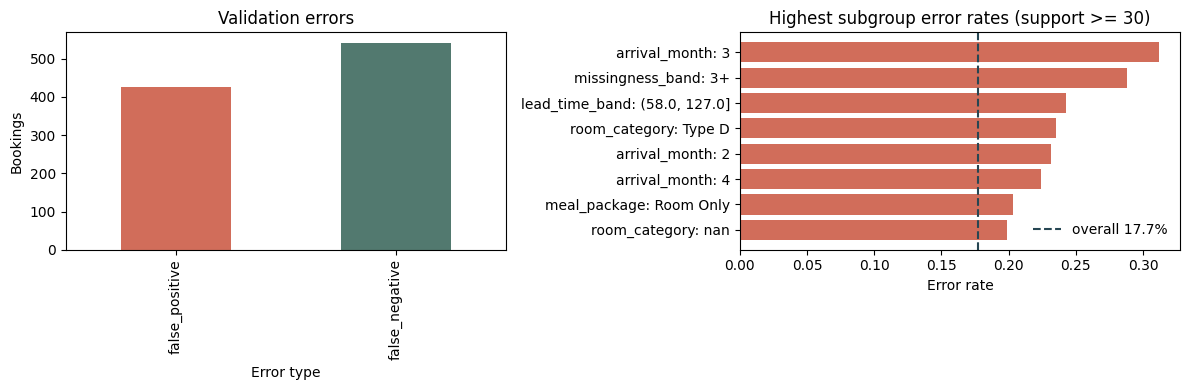

In [33]:
errors = val_set[['id'] + feature_columns].copy()
errors['actual'] = y_val
errors['predicted'] = validation_predictions[winner_name]
errors['error_type'] = np.select([
    errors['actual'].eq(0) & errors['predicted'].eq(1),
    errors['actual'].eq(1) & errors['predicted'].eq(0),
], ['false_positive', 'false_negative'], default='correct')

confusion = confusion_matrix(y_val, errors['predicted'], labels=[0, 1])
tn, fp, fn, tp = confusion.ravel()
overall_error_rate = (fp + fn) / len(errors)

# Show every baseline model confusion matrix as a comparable validation heatmap.
all_baseline_confusions = {
    **{f'from-scratch - {name}': matrix for name, matrix in scratch_confusions.items()},
    **{f'sklearn - {name}': matrix for name, matrix in comparison_confusions.items()},
}
columns = 4
rows = int(np.ceil(len(all_baseline_confusions) / columns))
vmax = max(matrix.max() for matrix in all_baseline_confusions.values())
fig, axes = plt.subplots(rows, columns, figsize=(14, 3.2 * rows), squeeze=False)
for ax, (name, matrix) in zip(axes.flat, all_baseline_confusions.items()):
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=vmax)
    ax.set(
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=['not canceled', 'canceled'],
        yticklabels=['not canceled', 'canceled'],
        xlabel='Predicted', ylabel='Actual', title=name,
    )
    ax.tick_params(axis='x', labelrotation=20)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(
            col, row, f'{value:,}', ha='center', va='center',
            color='white' if value > vmax * 0.55 else 'black',
        )
for ax in axes.flat[len(all_baseline_confusions):]:
    ax.remove()
fig.suptitle(
    'Confusion matrices for all baseline variants (validation set)', y=1.01
)
fig.tight_layout()
plt.show()
error_counts = errors['error_type'].value_counts().reindex(
    ['correct', 'false_positive', 'false_negative'], fill_value=0
)
error_summary = pd.DataFrame({
    'count': error_counts,
    'share_of_validation': error_counts / len(errors),
})
display(error_summary)
display(pd.DataFrame(
    [validation_metrics(y_val, errors['predicted'])], index=[winner_name]
))

# Find cases where the baseline variants do not agree on the validation row.
prediction_frame = pd.DataFrame(validation_predictions, index=val_set.index)
errors['model_disagreement'] = prediction_frame.nunique(axis=1).gt(1).to_numpy()
disagreement_summary = errors.groupby('model_disagreement', observed=True).agg(
    support=('error_type', 'size'),
    errors=('error_type', lambda values: values.ne('correct').sum()),
)
disagreement_summary['error_rate'] = (
    disagreement_summary['errors'] / disagreement_summary['support']
)
display(disagreement_summary.rename(
    index={False: 'model_agreement', True: 'model_disagreement'}
))

# Check whether missingness is associated with more validation errors.
errors['missing_feature_count'] = val_set[feature_columns].isna().sum(axis=1).to_numpy()
errors['missingness_band'] = pd.cut(
    errors['missing_feature_count'], [-1, 0, 2, np.inf],
    labels=['none', '1-2', '3+'],
)

slice_error_tables = {}
for column in (
    'booking_channel', 'meal_package', 'room_category', 'arrival_month',
    'missingness_band',
):
    grouped = errors.groupby(column, dropna=False, observed=True).agg(
        support=('error_type', 'size'),
        errors=('error_type', lambda values: values.ne('correct').sum()),
        false_positive=('error_type', lambda values: values.eq('false_positive').sum()),
        false_negative=('error_type', lambda values: values.eq('false_negative').sum()),
    )
    grouped['error_rate'] = grouped['errors'] / grouped['support']
    slice_error_tables[column] = grouped.loc[grouped['support'] >= 30].sort_values(
        'error_rate', ascending=False
    )

errors['lead_time_band'] = pd.qcut(
    errors['days_before_arrival'], q=4, duplicates='drop'
)
lead_time_errors = errors.groupby('lead_time_band', observed=True).agg(
    support=('error_type', 'size'),
    errors=('error_type', lambda values: values.ne('correct').sum()),
    false_positive=('error_type', lambda values: values.eq('false_positive').sum()),
    false_negative=('error_type', lambda values: values.eq('false_negative').sum()),
)
lead_time_errors['error_rate'] = (
    lead_time_errors['errors'] / lead_time_errors['support']
)
slice_error_tables['lead_time_band'] = lead_time_errors.loc[
    lead_time_errors['support'] >= 30
].sort_values('error_rate', ascending=False)

for column, summary in slice_error_tables.items():
    print(f'Validation error slices: {column} (groups with support >= 30)')
    display(summary)

numeric_error_profile = errors.groupby('error_type')[
    ['days_before_arrival', 'nightly_rate_idr', 'special_requests', 'num_children']
].median()
display(numeric_error_profile)

# Inspect representative mistakes, prioritizing bookings with longer lead time.
mistakes = errors.loc[errors['error_type'].ne('correct')].sort_values(
    'days_before_arrival', ascending=False, na_position='last'
)
display(mistakes[[
    'id', 'actual', 'predicted', 'error_type', 'days_before_arrival',
    'booking_channel', 'meal_package', 'room_category',
    'missing_feature_count', 'model_disagreement',
]].head(20))

top_slices = []
for column, summary in slice_error_tables.items():
    if not summary.empty:
        top = summary.head(3).reset_index()
        top['feature_group'] = column
        top['segment'] = top[column].astype(str)
        top_slices.append(top[['feature_group', 'segment', 'support', 'error_rate']])
top_error_slices = (
    pd.concat(top_slices, ignore_index=True).sort_values('error_rate', ascending=False)
    if top_slices else pd.DataFrame(
        columns=['feature_group', 'segment', 'support', 'error_rate']
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
error_counts.drop('correct').plot.bar(
    ax=axes[0], color=['#d16d5a', '#52796f']
)
axes[0].set(title='Validation errors', ylabel='Bookings', xlabel='Error type')
if not top_error_slices.empty:
    plot_slices = top_error_slices.head(8).copy()
    plot_slices['label'] = plot_slices['feature_group'] + ': ' + plot_slices['segment']
    axes[1].barh(
        plot_slices['label'][::-1], plot_slices['error_rate'][::-1],
        color='#d16d5a',
    )
    axes[1].axvline(
        overall_error_rate, color='#264653', linestyle='--',
        label=f'overall {overall_error_rate:.1%}',
    )
    axes[1].legend(frameon=False)
axes[1].set(
    title='Highest subgroup error rates (support >= 30)', xlabel='Error rate'
)
fig.tight_layout()
plt.show()
